- Random Forest doesn't need much of hyperparameter tuning. It is robust to overfitting and can handle large datasets with higher dimensionality.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv('heart.csv')

In [3]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
df.shape

(303, 14)

In [72]:
X = df.iloc[:,0:-1]
y = df.iloc[:,-1]

In [73]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [74]:
print(X_train.shape)
print(X_test.shape)

(242, 13)
(61, 13)


In [ ]:
# Create the models to see how Random Forest performs against other models
rf = RandomForestClassifier()
gb = GradientBoostingClassifier()
svc = SVC()
lr = LogisticRegression()

- Without hyperparameter tuning, random forest performs well compared to other models.

In [ ]:
rf.fit(X_train,y_train) 
y_pred = rf.predict(X_test)
accuracy_score(y_test,y_pred)

0.8524590163934426

In [79]:
gb.fit(X_train,y_train)
y_pred = gb.predict(X_test)
accuracy_score(y_test,y_pred)

0.7704918032786885

In [80]:
svc.fit(X_train,y_train)
y_pred = svc.predict(X_test)
accuracy_score(y_test,y_pred)

0.7049180327868853

In [81]:
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
accuracy_score(y_test,y_pred)

C:\Users\91842\anaconda3\lib\site-packages\sklearn\linear_model\_logistic.py:763: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8852459016393442

In [ ]:
# With even very less hyperparameter tuning, Random Forest is able to fit the data better 
rf = RandomForestClassifier(max_samples=0.75,random_state=42)
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
accuracy_score(y_test,y_pred)

0.9016393442622951

In [85]:
from sklearn.model_selection import cross_val_score
np.mean(cross_val_score(RandomForestClassifier(max_samples=0.75),X,y,cv=10,scoring='accuracy'))

0.8412903225806451

### Use GridSearchCV/RandomizedSearchCV to find the best hyperparameters for Random Forest

### GridSearchCV

In [ ]:
# Number of trees in random forest
n_estimators = [20,60,100,120] # 4 possible values

# Number of features to consider at every split
max_features = [0.2,0.6,1.0] # 3 possible values

# Maximum number of levels in tree
max_depth = [2,8,None] # 3 possible values

# Number of samples
max_samples = [0.5,0.75,1.0] # 3 possible values

# 108 (4*3*3*3) diff random forest will be created with all possible combinations of the above hyperparameters. We will use GridSearchCV to find the best hyperparameters for Random Forest.

In [87]:
param_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
              'max_samples':max_samples
             }
print(param_grid)

{'n_estimators': [20, 60, 100, 120], 'max_features': [0.2, 0.6, 1.0], 'max_depth': [2, 8, None], 'max_samples': [0.5, 0.75, 1.0]}


In [88]:
rf = RandomForestClassifier()

- Cv = 5: Number of folds in cross-validation. It means that the training data will be split into 5 parts, and the model will be trained on 4 parts and validated on the remaining part. This process will be repeated 5 times, with each part being used as the validation set once.

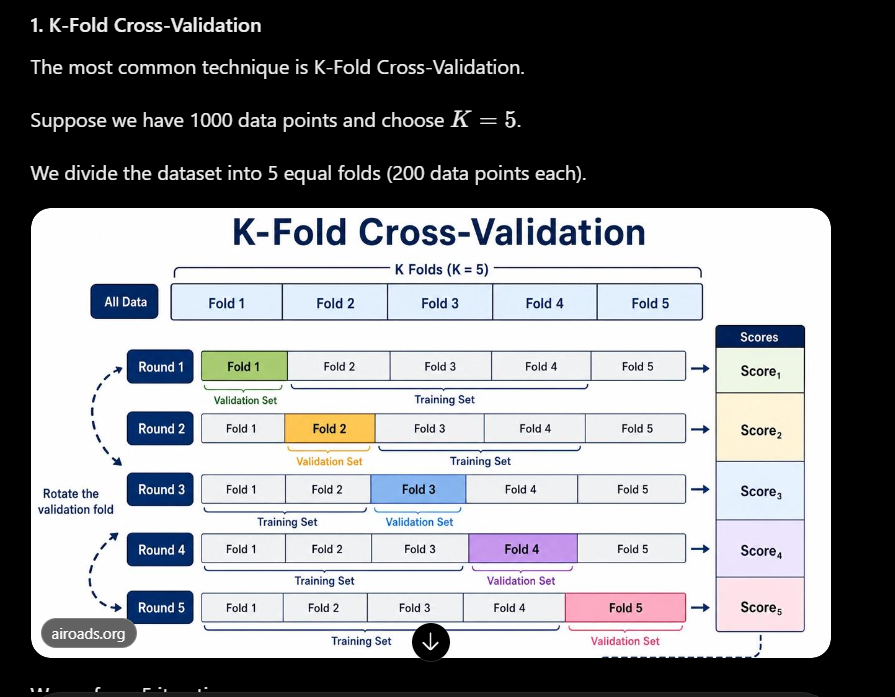


In [89]:
from sklearn.model_selection import GridSearchCV

rf_grid = GridSearchCV(estimator = rf, 
                       param_grid = param_grid, 
                       cv = 5, 
                       verbose=2, 
                       n_jobs = -1)

In [90]:
rf_grid.fit(X_train,y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


C:\Users\91842\anaconda3\lib\site-packages\sklearn\model_selection\_search.py:918: UserWarning: One or more of the test scores are non-finite: [0.78894558 0.80552721 0.82627551 0.81802721 0.82219388 0.80552721
 0.81802721 0.81794218        nan        nan        nan        nan
 0.77236395 0.81394558 0.80986395 0.80977891 0.79761905 0.80161565
 0.80994898 0.80986395        nan        nan        nan        nan
 0.78920068 0.80170068 0.80994898 0.80170068 0.77695578 0.80153061
 0.79336735 0.80578231        nan        nan        nan        nan
 0.80161565 0.80960884 0.79753401 0.82202381 0.78903061 0.82636054
 0.82219388 0.83035714        nan        nan        nan        nan
 0.79753401 0.79753401 0.80569728 0.80986395 0.78103741 0.78095238
 0.80153061 0.80178571        nan        nan        nan        nan
 0.80170068 0.80144558 0.79753401 0.80969388 0.80178571 0.78920068
 0.80586735 0.80578231        nan        nan        nan        nan
 0.81802721 0.82219388 0.80569728 0.82236395 0.830697

GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [2, 8, None],
                         'max_features': [0.2, 0.6, 1.0],
                         'max_samples': [0.5, 0.75, 1.0],
                         'n_estimators': [20, 60, 100, 120]},
             verbose=2)

In [91]:
rf_grid.best_params_

{'max_depth': None,
 'max_features': 0.2,
 'max_samples': 0.75,
 'n_estimators': 20}

In [92]:
rf_grid.best_score_

0.8306972789115645

### RandomSearchCV

- Here it instead of trying all possible combinations of hyperparameters, it randomly selects a fixed number of hyperparameter combinations from the specified hyperparameter space. This can be more efficient when the hyperparameter space is large.

- It is not guaranteed to find the best hyperparameters, but it can often find good hyperparameters in less time than GridSearchCV.

In [93]:
# Number of trees in random forest
n_estimators = [20,60,100,120]

# Number of features to consider at every split
max_features = [0.2,0.6,1.0]

# Maximum number of levels in tree
max_depth = [2,8,None]

# Number of samples
max_samples = [0.5,0.75,1.0]

# Bootstrap samples
bootstrap = [True,False]

# Minimum number of samples required to split a node
min_samples_split = [2, 5]

# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2]

In [94]:
param_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
              'max_samples':max_samples,
              'bootstrap':bootstrap,
              'min_samples_split':min_samples_split,
              'min_samples_leaf':min_samples_leaf
             }
print(param_grid)

{'n_estimators': [20, 60, 100, 120], 'max_features': [0.2, 0.6, 1.0], 'max_depth': [2, 8, None], 'max_samples': [0.5, 0.75, 1.0], 'bootstrap': [True, False], 'min_samples_split': [2, 5], 'min_samples_leaf': [1, 2]}


In [95]:
from sklearn.model_selection import RandomizedSearchCV

rf_grid = RandomizedSearchCV(estimator = rf, 
                       param_distributions = param_grid, 
                       cv = 5, 
                       verbose=2, 
                       n_jobs = -1)

In [96]:
rf_grid.fit(X_train,y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


C:\Users\91842\anaconda3\lib\site-packages\sklearn\model_selection\_search.py:918: UserWarning: One or more of the test scores are non-finite: [0.81785714 0.81411565 0.76454082 0.80977891 0.79328231        nan
 0.81377551 0.80986395 0.80170068        nan]
  warnings.warn(


RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': [2, 8, None],
                                        'max_features': [0.2, 0.6, 1.0],
                                        'max_samples': [0.5, 0.75, 1.0],
                                        'min_samples_leaf': [1, 2],
                                        'min_samples_split': [2, 5],
                                        'n_estimators': [20, 60, 100, 120]},
                   verbose=2)

In [97]:
rf_grid.best_params_

{'n_estimators': 120,
 'min_samples_split': 2,
 'min_samples_leaf': 2,
 'max_samples': 0.75,
 'max_features': 0.2,
 'max_depth': None,
 'bootstrap': True}

In [98]:
rf_grid.best_score_

0.8178571428571428